# Dong 2020 Prostate — 02 Manifold
**Gate 1 = GO** (shown in 01: sample-integrated across the theta sweep, single connected continuous manifold).

Topology is read from the **embedding**, not a scalar. The developmental compartment is an elongated, non-branching strip -> fit a scFates **`curve`** (not a `tree`). The curve is fit on the **committed UMAP** (no re-embedding of the linear compartment - that would fold an elongated strip into a U/W) and its **actual edges are rendered** on the manifold to confirm it is fold-free.

In [1]:
import os, sys
os.environ['R_HOME'] = '/home/caleb/miniconda3/envs/scFates/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scFates as scf
import matplotlib.pyplot as plt
from scipy.stats import spearmanr, pearsonr
from scipy.spatial.distance import pdist, squareform
from scipy.sparse.csgraph import connected_components
sc.settings.verbosity = 1; np.random.seed(1)

In [2]:
name = os.path.split(os.getcwd())[1]
pth      = os.path.join('..', '..', '..', '..')
pth_in   = os.path.join(pth, 'data', 'cancer', 'vertebrate', 'CCCA', 'claude', 'Prostate', name)
pth_out  = os.path.join(pth, 'figures', 'mesencontext', 'claude', 'Prostate', name)

In [3]:
adata = sc.read_h5ad(os.path.join(pth_in, 'processed.h5ad')); adata

AnnData object with n_obs × n_vars = 9698 × 15672
    obs: 'sample', 'cell_type', 'complexity', 'umap1', 'umap2', 'g1s_score', 'g2m_score', 'cell_cycle_phase', 'mp_top_score', 'mp_top', 'mp_assignment', 'celltype', 'S_score', 'G2M_score', 'phase', 'leiden', 'compartment', 'GSE162534', 'GSE229103', 'rRNAModifications', 'Gast', 'pSom', 'Crest', 'AR_luminal', 'NE_program', 'lineage'
    var: 'n_cells', 'm', 'v', 'n_obs', 'res', 'lp', 'lpa', 'qv', 'highly_variable'
    uns: 'compartment_colors', 'leiden', 'log1p', 'neighbors', 'pca', 'phase_colors', 'sample_colors', 'umap'
    obsm: 'X_pca', 'X_pca_harmony', 'X_umap', 'harm_th0', 'harm_th10', 'harm_th2', 'harm_th5'
    varm: 'PCs'
    obsp: 'connectivities', 'distances'

### Scope the trajectory to the developmental compartment
The proliferative compartment (set aside in 01) confounds the Gast/pSom-high developmental origin and is excluded from the fit. Keeping the committed embedding coordinates (no re-embed), the developmental subset is a single connected component.

In [4]:
sub = adata[adata.obs.compartment == 'Developmental'].copy()
sc.pp.neighbors(sub, n_pcs=20, n_neighbors=30, use_rep='X_pca_harmony', random_state=1)
ncomp, _ = connected_components(sub.obsp['connectivities'], directed=False)
print('developmental cells:', sub.n_obs, '| kNN components:', ncomp)

developmental cells: 8281 | kNN components: 1


### Topology from the embedding — `curve` vs `tree`
A forced PPT tree over-segments with node count (tips/forks proliferate as `Nodes` rises while the extra tips co-vary in Gast & pSom rather than separating into competing arms) - i.e. node-density wander, not a true bifurcation. The stable low-node topology is a single 2-tip axis, so the manifold is **non-branching** and the appropriate model is a `curve`.

In [5]:
print('forced-tree tip/fork count vs Nodes (over-segmentation check):')
for N in [10, 15, 20, 30, 50]:
    scf.tl.tree(sub, method='ppt', Nodes=N, use_rep='X_umap', ppt_lambda=100, ppt_sigma=0.5, seed=1)
    dg = sub.uns['graph']['B'].sum(0)
    print(f'  Nodes={N:3d}: tips={int((dg==1).sum())} forks={int((dg>2).sum())}')

forced-tree tip/fork count vs Nodes (over-segmentation check):
inferring a principal tree --> parameters used 
    10 principal points, sigma = 0.5, lambda = 100, metric = euclidean
    fitting:  54%|#####4    | 27/50 [00:01<00:00, 26.08it/s]
    converged
    finished (0:00:01) --> added 
    .uns['ppt'], dictionnary containing inferred tree.
    .obsm['X_R'] soft assignment of cells to principal points.
    .uns['graph']['B'] adjacency matrix of the principal points.
    .uns['graph']['F'] coordinates of principal points in representation space.
  Nodes= 10: tips=4 forks=2
inferring a principal tree --> parameters used 
    15 principal points, sigma = 0.5, lambda = 100, metric = euclidean
    fitting:  50%|#####     | 25/50 [00:00<00:00, 235.96it/s]
    converged
    finished (0:00:00) --> added 
    .uns['ppt'], dictionnary containing inferred tree.
    .obsm['X_R'] soft assignment of cells to principal points.
    .uns['graph']['B'] adjacency matrix of the principal points.
    .u

### Fit the principal `curve` on the committed UMAP

In [6]:
scf.tl.curve(sub, Nodes=20, use_rep='X_umap', epg_lambda=0.3, epg_mu=100, seed=1)
B = sub.uns['graph']['B']; dg = B.sum(0)
print('curve: tips =', int((dg==1).sum()), '| forks =', int((dg>2).sum()))

inferring a principal curve --> parameters used 
    20 principal points, mu = 100, lambda = 0.3
    finished (0:00:01) --> added 
    .uns['epg'] dictionnary containing inferred elastic curve generated from elpigraph.
    .obsm['X_R'] soft assignment of cells to principal points.
    .uns['graph']['B'] adjacency matrix of the principal points.
    .uns['graph']['F'], coordinates of principal points in representation space.
curve: tips = 2 | forks = 0


### Fold-free check — render the ACTUAL curve edges + self-approach ratio
Not judged with a UMAP-neighbour metric (blind to folds by construction). The **self-approach ratio** = min distance between non-adjacent nodes / median edge length; > ~1.5 means the curve never doubles back on itself (no U/W seam).

In [7]:
R = sub.obsm['X_R']
node = (R.T @ sub.obsm['X_umap']) / R.sum(0)[:, None]
D = squareform(pdist(node))
edges = [(i,j) for i in range(len(node)) for j in range(i+1,len(node)) if B[i,j] > 0]
edlen = np.median([D[i,j] for i,j in edges])
nonadj = [D[i,j] for i in range(len(node)) for j in range(i+2,len(node)) if B[i,j]==0]
print(f'self-approach ratio = {min(nonadj)/edlen:.2f}  (> ~1.5 = fold-free)')

self-approach ratio = 1.74  (> ~1.5 = fold-free)


### Root at the Gast/pSom-high developmental origin
Root is set at the tip with the highest Gast+pSom (the developmental origin), **not** the Crest-high tip (Crest is developmentally late/terminal) and **not** a proliferation state (excluded).

In [8]:
tips = np.where(dg==1)[0]
ngp  = (R.T @ (sub.obs.Gast + sub.obs.pSom).values) / R.sum(0)
ncr  = (R.T @ sub.obs.Crest.values) / R.sum(0)
root = int(tips[np.argmax(ngp[tips])])
print('tips', list(tips), '| Gast+pSom@tips', ngp[tips].round(3), '| Crest@tips', ncr[tips].round(3), '| root', root)
scf.tl.root(sub, root)
scf.tl.pseudotime(sub, n_jobs=4, seed=1)

tips [np.int64(0), np.int64(2)] | Gast+pSom@tips [0.078 0.204] | Crest@tips [-0.01  -0.063] | root 2
node 2 selected as a root --> added
    .uns['graph']['root'] selected root.
    .uns['graph']['pp_info'] for each PP, its distance vs root and segment assignment.
    .uns['graph']['pp_seg'] segments network information.
projecting cells onto the principal graph
    finished (0:00:01) --> added
    .obs['edge'] assigned edge.
    .obs['t'] pseudotime value.
    .obs['seg'] segment of the tree assigned.
    .obs['milestones'] milestone assigned.
    .uns['pseudotime_list'] list of cell projection from all mappings.


In [9]:
# signature gradients along pseudotime (origin Gast/pSom-high -> terminus Crest-high)
for m in ['Gast','pSom','Crest','AR_luminal','NE_program']:
    print(f'  {m:11s} vs pt  rho = {spearmanr(sub.obs.t, sub.obs[m])[0]:+.3f}')
# continuity on an INDEPENDENT diffusion embedding (not the UMAP the curve was fit on)
sc.tl.diffmap(sub, n_comps=10)
print('continuity corr(pt, DC1) [independent] =', round(pearsonr(sub.obs.t, sub.obsm['X_diffmap'][:,1])[0], 3))

  Gast        vs pt  rho = -0.211
  pSom        vs pt  rho = -0.406
  Crest       vs pt  rho = +0.385
  AR_luminal  vs pt  rho = +0.121
  NE_program  vs pt  rho = -0.170
continuity corr(pt, DC1) [independent] = -0.79


In [10]:
# rename milestones by biological role at each tip
ms = {str(root): 'Developmental_origin'}
other = [t for t in tips if t != root]
for t in other: ms[str(t)] = 'Neural_crest_terminus'
scf.tl.rename_milestones(sub, new=ms)
print(sub.obs.milestones.value_counts())

milestones
Neural_crest_terminus    4538
Developmental_origin     3743
Name: count, dtype: int64


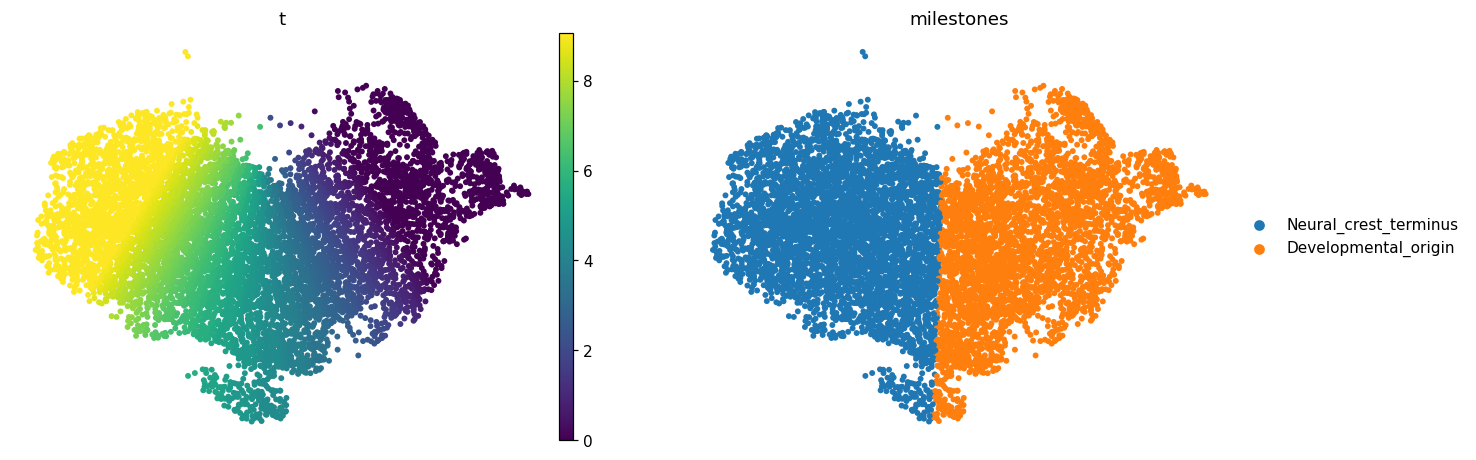

In [11]:
# pseudotime + milestones on the manifold
sc.pl.umap(sub, color=['t','milestones'], size=60, frameon=False)

### Manifold figure (reference style) — pseudotime with curve edges + fold-free confirmation

saved ../../../../../../figures/cancer/vertebrate/CCCA/Claude/Prostate/Dong2020_Prostate-5/manifold.pdf


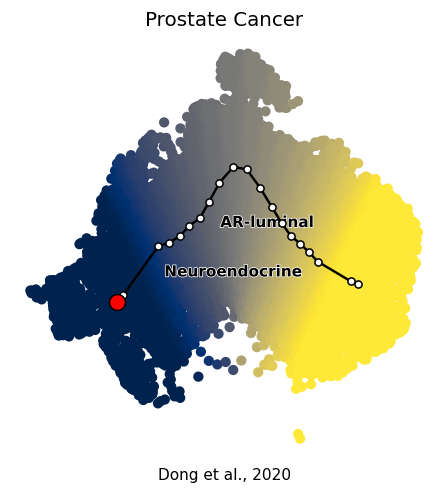

In [12]:
fig, ax = plt.subplots(1, 1, figsize=(5, 5))
sc.pl.umap(sub, color='t', cmap='cividis', size=180, colorbar_loc=None, frameon=False, show=False, ax=ax)
for i,j in edges: ax.plot([node[i,0],node[j,0]], [node[i,1],node[j,1]], '-k', lw=1.6, zorder=10)
ax.scatter(node[:,0], node[:,1], c='w', edgecolor='k', s=22, zorder=11)
ax.scatter(node[root,0], node[root,1], c='red', edgecolor='k', s=110, zorder=12)
sc.pl.umap(sub, color='celltype', size=180, alpha=0, legend_loc='on data',
           legend_fontoutline=1, frameon=False, show=False, ax=ax)
ax.invert_yaxis(); ax.invert_xaxis()
ax.set_title('Prostate Cancer', size=13)
ax.text(.5, -.05, 'Dong et al., 2020', ha='center', transform=ax.transAxes)
fn = os.path.join(pth_out, 'manifold.pdf'); plt.savefig(fn, bbox_inches='tight'); plt.show()
print('saved', fn)

### Save manifold
The scFates ElPiGraph report (`uns['epg']`) holds a ragged list that h5py cannot serialize; it is dropped before writing (the fitted trajectory itself lives in `uns['graph']` + `obsm['X_R']`, both retained).

In [13]:
sub.uns.pop('epg', None)
sub.write(os.path.join(pth_in, 'manifold.h5ad'))
print('saved', os.path.join(pth_in, 'manifold.h5ad'), sub.shape)

saved ../../../../../../data/cancer/vertebrate/CCCA/Claude/Prostate/Dong2020_Prostate-5/manifold.h5ad (8281, 15672)
